<a href="https://colab.research.google.com/github/sats-11/sentimentia-0/blob/main/Distilbert.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:


!pip install -q transformers datasets accelerate scikit-learn pandas numpy matplotlib seaborn

print("Libraries installed successfully!")


Libraries installed successfully!


In [8]:


import os
import random
import time
import copy

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader

from transformers import (
    AutoTokenizer,
    AutoModel,
    get_linear_schedule_with_warmup
)

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("All imports completed!")


All imports completed!


In [9]:

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU unavailable. Enable GPU in Colab.")

print("Random seed:", SEED)


Device: cuda
GPU: Tesla T4
Random seed: 42


In [10]:
import pandas as pd

df = pd.read_csv("/content/emotion_dataset_raw.csv")

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())

Dataset shape: (34792, 2)

Column names:
['Emotion', 'Text']


,Emotion,Text
0,neutral,Why ?
1,joy,Sage Act upgrade on my to do list for tommorow.
2,sadness,ON THE WAY TO MY HOMEGIRL BABY FUNERAL!!! MAN ...
3,joy,Such an eye ! The true hazel eye-and so brill...
4,joy,@Iluvmiasantos ugh babe.. hugggzzz for u .! b...


In [11]:
print("Original dataset shape:", df.shape)

print("\nDataset columns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nEmotion distribution:")
print(df["Emotion"].value_counts())

# Keep only required columns
df = df[["Text", "Emotion"]].copy()

# Remove missing values
df = df.dropna(subset=["Text", "Emotion"])

# Convert to strings and remove extra spaces
df["Text"] = df["Text"].astype(str).str.strip()
df["Emotion"] = df["Emotion"].astype(str).str.strip()

# Remove empty text
df = df[
    (df["Text"] != "") &
    (df["Emotion"] != "")
].copy()

# Remove exact duplicate text-label pairs
df = df.drop_duplicates(
    subset=["Text", "Emotion"]
).reset_index(drop=True)

print("\nCleaned dataset shape:", df.shape)

display(df.head())


Original dataset shape: (34792, 2)

Dataset columns:
['Emotion', 'Text']

Missing values:
Emotion    0
Text       0
dtype: int64

Emotion distribution:
Emotion
joy         11045
sadness      6722
fear         5410
anger        4297
surprise     4062
neutral      2254
disgust       856
shame         146
Name: count, dtype: int64

Cleaned dataset shape: (31147, 2)


,Text,Emotion
0,Why ?,neutral
1,Sage Act upgrade on my to do list for tommorow.,joy
2,ON THE WAY TO MY HOMEGIRL BABY FUNERAL!!! MAN ...,sadness
3,Such an eye ! The true hazel eye-and so brilli...,joy
4,@Iluvmiasantos ugh babe.. hugggzzz for u .! b...,joy


In [13]:


label_encoder = LabelEncoder()

df["label"] = label_encoder.fit_transform(
    df["Emotion"]
)

num_labels = len(label_encoder.classes_)

label2id = {
    label: int(i)
    for i, label in enumerate(label_encoder.classes_)
}

id2label = {
    int(i): label
    for i, label in enumerate(label_encoder.classes_)
}

print("Number of emotion classes:", num_labels)
print("\nLabel mapping:")
print(label2id)

print("\nEncoded dataset:")
display(df.head())


Number of emotion classes: 8

Label mapping:
{'anger': 0, 'disgust': 1, 'fear': 2, 'joy': 3, 'neutral': 4, 'sadness': 5, 'shame': 6, 'surprise': 7}

Encoded dataset:


,Text,Emotion,label
0,Why ?,neutral,4
1,Sage Act upgrade on my to do list for tommorow.,joy,3
2,ON THE WAY TO MY HOMEGIRL BABY FUNERAL!!! MAN ...,sadness,5
3,Such an eye ! The true hazel eye-and so brilli...,joy,3
4,@Iluvmiasantos ugh babe.. hugggzzz for u .! b...,joy,3


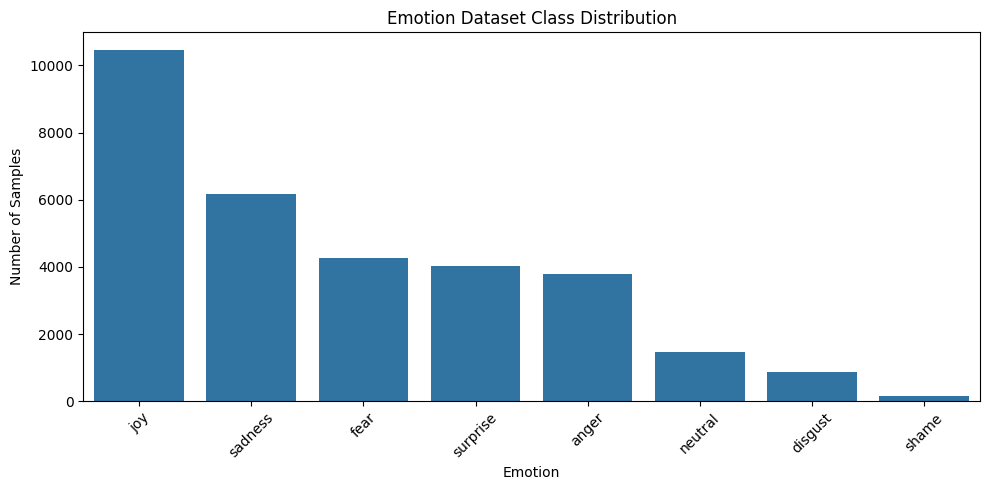

In [14]:



plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="Emotion",
    order=df["Emotion"].value_counts().index
)

plt.title("Emotion Dataset Class Distribution")
plt.xlabel("Emotion")
plt.ylabel("Number of Samples")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [15]:

train_df, temp_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label"]
)

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Test samples:", len(test_df))

print("\nTraining distribution:")
print(train_df["Emotion"].value_counts())

print("\nValidation distribution:")
print(val_df["Emotion"].value_counts())

print("\nTest distribution:")
print(test_df["Emotion"].value_counts())


Training samples: 24917
Validation samples: 3115
Test samples: 3115

Training distribution:
Emotion
joy         8371
sadness     4939
fear        3410
surprise    3212
anger       3020
neutral     1166
disgust      684
shame        115
Name: count, dtype: int64

Validation distribution:
Emotion
joy         1046
sadness      617
fear         426
surprise     402
anger        377
neutral      146
disgust       86
shame         15
Name: count, dtype: int64

Test distribution:
Emotion
joy         1047
sadness      618
fear         426
surprise     401
anger        378
neutral      146
disgust       85
shame         14
Name: count, dtype: int64


In [17]:

MODEL_NAME = "bert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

bert_encoder = AutoModel.from_pretrained(MODEL_NAME)

bert_encoder = bert_encoder.to(device)

# Initially freeze BERT parameters.
# We will train the BiLSTM and Attention layers first.
for param in bert_encoder.parameters():
    param.requires_grad = False

bert_encoder.eval()

print("BERT tokenizer loaded successfully!")
print("BERT encoder loaded successfully!")

print("Hidden size:", bert_encoder.config.hidden_size)
print("Number of layers:", bert_encoder.config.num_hidden_layers)
print("Vocabulary size:", tokenizer.vocab_size)
print("Device:", device)


model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BERT tokenizer loaded successfully!
BERT encoder loaded successfully!
Hidden size: 768
Number of layers: 12
Vocabulary size: 30522
Device: cuda


In [18]:
MAX_LENGTH = 128

def tokenize_texts(texts):
    return tokenizer(
        texts.tolist(),
        max_length=MAX_LENGTH,
        padding="max_length",
        truncation=True,
        return_attention_mask=True,
        return_tensors="pt"
    )

train_encodings = tokenize_texts(train_df["Text"])
val_encodings = tokenize_texts(val_df["Text"])
test_encodings = tokenize_texts(test_df["Text"])

print("Training input shape:", train_encodings["input_ids"].shape)
print("Validation input shape:", val_encodings["input_ids"].shape)
print("Testing input shape:", test_encodings["input_ids"].shape)


Training input shape: torch.Size([24917, 128])
Validation input shape: torch.Size([3115, 128])
Testing input shape: torch.Size([3115, 128])


In [19]:

class EmotionDataset(Dataset):

    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = torch.tensor(
            labels.to_numpy(),
            dtype=torch.long
        )

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return {
            "input_ids": self.encodings["input_ids"][idx],
            "attention_mask": self.encodings["attention_mask"][idx],
            "labels": self.labels[idx]
        }


train_dataset = EmotionDataset(
    train_encodings, train_df["label"]
)

val_dataset = EmotionDataset(
    val_encodings, val_df["label"]
)

test_dataset = EmotionDataset(
    test_encodings, test_df["label"]
)

print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Testing dataset:", len(test_dataset))

sample = train_dataset[0]

print("\nSample input shape:", sample["input_ids"].shape)
print("Sample attention mask shape:", sample["attention_mask"].shape)
print("Sample label:", sample["labels"].item())


Training dataset: 24917
Validation dataset: 3115
Testing dataset: 3115

Sample input shape: torch.Size([128])
Sample attention mask shape: torch.Size([128])
Sample label: 5


In [21]:


class BERT_BiLSTM_Attention(nn.Module):

    def __init__(
        self,
        bert_model,
        hidden_size=256,
        num_classes=8,
        dropout=0.3
    ):
        super(BERT_BiLSTM_Attention, self).__init__()

        self.bert = bert_model

        # Bidirectional LSTM
        self.lstm = nn.LSTM(
            input_size=768,
            hidden_size=hidden_size,
            num_layers=1,
            batch_first=True,
            bidirectional=True
        )

        # Attention layer
        self.attention = nn.Linear(
            hidden_size * 2, 1
        )

        # Classification layers
        self.dropout = nn.Dropout(dropout)

        self.classifier = nn.Linear(
            hidden_size * 2,
            num_classes
        )

    def forward(self, input_ids, attention_mask):

        # Extract contextual token embeddings
        with torch.no_grad():
            bert_outputs = self.bert(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

        sequence_output = bert_outputs.last_hidden_state

        # BiLSTM
        lstm_output, _ = self.lstm(sequence_output)

        # Calculate attention scores
        attention_scores = self.attention(
            lstm_output
        ).squeeze(-1)

        # Mask padding tokens
        attention_scores = attention_scores.masked_fill(
            attention_mask == 0,
            -1e9
        )

        attention_weights = torch.softmax(
            attention_scores,
            dim=1
        )

        # Weighted context vector
        context_vector = torch.sum(
            lstm_output * attention_weights.unsqueeze(-1),
            dim=1
        )

        # Classification
        context_vector = self.dropout(context_vector)

        logits = self.classifier(context_vector)

        return logits


In [22]:

model = BERT_BiLSTM_Attention(
    bert_model=bert_encoder,
    hidden_size=256,
    num_classes=num_labels,
    dropout=0.3
)

model = model.to(device)

print(model)

total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("\nTotal parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")


BERT_BiLSTM_Attention(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e-

In [23]:

BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))


Training batches: 1558
Validation batches: 195
Testing batches: 195


In [24]:

batch = next(iter(train_loader))

input_ids = batch["input_ids"].to(device)
attention_mask = batch["attention_mask"].to(device)

model.eval()

with torch.no_grad():
    outputs = model(
        input_ids=input_ids,
        attention_mask=attention_mask
    )

print("Input shape:", input_ids.shape)
print("Model output shape:", outputs.shape)

print("\nExpected output shape:")
print(f"({BATCH_SIZE}, {num_labels})")

assert outputs.shape == (BATCH_SIZE, num_labels)

print("\nForward pass successful!")


Input shape: torch.Size([16, 128])
Model output shape: torch.Size([16, 8])

Expected output shape:
(16, 8)

Forward pass successful!


In [25]:

from torch.optim import AdamW
from sklearn.metrics import f1_score
import copy
import time

EPOCHS = 10
LEARNING_RATE = 1e-3
PATIENCE = 3

criterion = nn.CrossEntropyLoss()

optimizer = AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LEARNING_RATE,
    weight_decay=0.01
)

total_steps = len(train_loader) * EPOCHS

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(0.1 * total_steps),
    num_training_steps=total_steps
)

print("Loss function: CrossEntropyLoss")
print("Optimizer: AdamW")
print("Learning rate:", LEARNING_RATE)
print("Maximum epochs:", EPOCHS)
print("Early stopping patience:", PATIENCE)


Loss function: CrossEntropyLoss
Optimizer: AdamW
Learning rate: 0.001
Maximum epochs: 10
Early stopping patience: 3


In [26]:

def train_one_epoch(model, loader, optimizer, scheduler):
    model.train()
    model.bert.eval()

    total_loss = 0
    all_preds = []
    all_labels = []

    for batch in loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad()

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        loss = criterion(outputs, labels)
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(), max_norm=1.0
        )

        optimizer.step()
        scheduler.step()

        total_loss += loss.item()

        predictions = torch.argmax(outputs, dim=1)

        all_preds.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    avg_loss = total_loss / len(loader)

    macro_f1 = f1_score(
        all_labels,
        all_preds,
        average="macro",
        zero_division=0
    )

    return avg_loss, macro_f1


def evaluate_model(model, loader):
    model.eval()

    total_loss = 0
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for batch in loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            loss = criterion(outputs, labels)
            total_loss += loss.item()

            predictions = torch.argmax(outputs, dim=1)

            all_preds.extend(predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    avg_loss = total_loss / len(loader)

    accuracy = accuracy_score(all_labels, all_preds)

    macro_f1 = f1_score(
        all_labels,
        all_preds,
        average="macro",
        zero_division=0
    )

    return avg_loss, accuracy, macro_f1, all_labels, all_preds


In [27]:

history = []

best_val_f1 = 0
best_model_state = None
patience_counter = 0

training_start = time.time()

for epoch in range(EPOCHS):

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")

    train_loss, train_f1 = train_one_epoch(
        model,
        train_loader,
        optimizer,
        scheduler
    )

    val_loss, val_accuracy, val_f1, _, _ = evaluate_model(
        model,
        val_loader
    )

    history.append({
        "Epoch": epoch + 1,
        "Training Loss": train_loss,
        "Training Macro F1": train_f1,
        "Validation Loss": val_loss,
        "Validation Accuracy": val_accuracy,
        "Validation Macro F1": val_f1
    })

    print(f"Training Loss: {train_loss:.4f}")
    print(f"Training Macro F1: {train_f1:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_accuracy:.4f}")
    print(f"Validation Macro F1: {val_f1:.4f}")

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_model_state = copy.deepcopy(model.state_dict())
        patience_counter = 0

        torch.save(
            best_model_state,
            "/content/best_bert_bilstm_attention.pt"
        )

        print("Best model checkpoint saved!")

    else:
        patience_counter += 1
        print("No validation improvement.")

    if patience_counter >= PATIENCE:
        print("\nEarly stopping triggered.")
        break

training_time = time.time() - training_start

# Restore best checkpoint
if best_model_state is not None:
    model.load_state_dict(best_model_state)

print("\nTraining completed!")
print("Best Validation Macro F1:", round(best_val_f1, 4))
print("Training time:", round(training_time / 60, 2), "minutes")

history_df = pd.DataFrame(history)
display(history_df.round(4))



Epoch 1/10
Training Loss: 1.2646
Training Macro F1: 0.4055
Validation Loss: 1.0448
Validation Accuracy: 0.6234
Validation Macro F1: 0.5773
Best model checkpoint saved!

Epoch 2/10
Training Loss: 0.9805
Training Macro F1: 0.6138
Validation Loss: 0.9318
Validation Accuracy: 0.6722
Validation Macro F1: 0.6528
Best model checkpoint saved!

Epoch 3/10
Training Loss: 0.8366
Training Macro F1: 0.6868
Validation Loss: 0.8880
Validation Accuracy: 0.6886
Validation Macro F1: 0.6720
Best model checkpoint saved!

Epoch 4/10
Training Loss: 0.6918
Training Macro F1: 0.7467
Validation Loss: 0.9126
Validation Accuracy: 0.6889
Validation Macro F1: 0.6805
Best model checkpoint saved!

Epoch 5/10
Training Loss: 0.5283
Training Macro F1: 0.8148
Validation Loss: 0.9636
Validation Accuracy: 0.6841
Validation Macro F1: 0.6659
No validation improvement.

Epoch 6/10
Training Loss: 0.3619
Training Macro F1: 0.8756
Validation Loss: 1.0634
Validation Accuracy: 0.6851
Validation Macro F1: 0.6741
No validation imp

,Epoch,Training Loss,Training Macro F1,Validation Loss,Validation Accuracy,Validation Macro F1
0,1,1.2646,0.4055,1.0448,0.6234,0.5773
1,2,0.9805,0.6138,0.9318,0.6722,0.6528
2,3,0.8366,0.6868,0.8880,0.6886,0.6720
3,4,0.6918,0.7467,0.9126,0.6889,0.6805
4,5,0.5283,0.8148,0.9636,0.6841,0.6659
5,6,0.3619,0.8756,1.0634,0.6851,0.6741
6,7,0.2153,0.9279,1.1833,0.6947,0.6722


In [28]:

best_state = torch.load(
    "/content/best_bert_bilstm_attention.pt",
    map_location=device,
    weights_only=True
)

model.load_state_dict(best_state)
model.eval()

test_loss, test_accuracy, test_macro_f1, y_true, y_pred = (
    evaluate_model(model, test_loader)
)

test_macro_precision = precision_score(
    y_true, y_pred,
    average="macro",
    zero_division=0
)

test_macro_recall = recall_score(
    y_true, y_pred,
    average="macro",
    zero_division=0
)

print("BERT + BiLSTM + Attention — Test Results")
print("-----------------------------------------")
print("Test Loss:", round(test_loss, 4))
print("Accuracy:", round(test_accuracy, 4))
print("Macro Precision:", round(test_macro_precision, 4))
print("Macro Recall:", round(test_macro_recall, 4))
print("Macro F1:", round(test_macro_f1, 4))

print("\nClassification Report:\n")

print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(num_labels),
    target_names=label_encoder.classes_,
    zero_division=0
))


BERT + BiLSTM + Attention — Test Results
-----------------------------------------
Test Loss: 0.9372
Accuracy: 0.6803
Macro Precision: 0.6675
Macro Recall: 0.6579
Macro F1: 0.6607

Classification Report:

              precision    recall  f1-score   support

       anger       0.64      0.60      0.62       378
     disgust       0.45      0.35      0.39        85
        fear       0.67      0.69      0.68       426
         joy       0.75      0.77      0.76      1047
     neutral       0.69      0.77      0.72       146
     sadness       0.63      0.68      0.65       618
       shame       0.86      0.86      0.86        14
    surprise       0.67      0.54      0.60       401

    accuracy                           0.68      3115
   macro avg       0.67      0.66      0.66      3115
weighted avg       0.68      0.68      0.68      3115



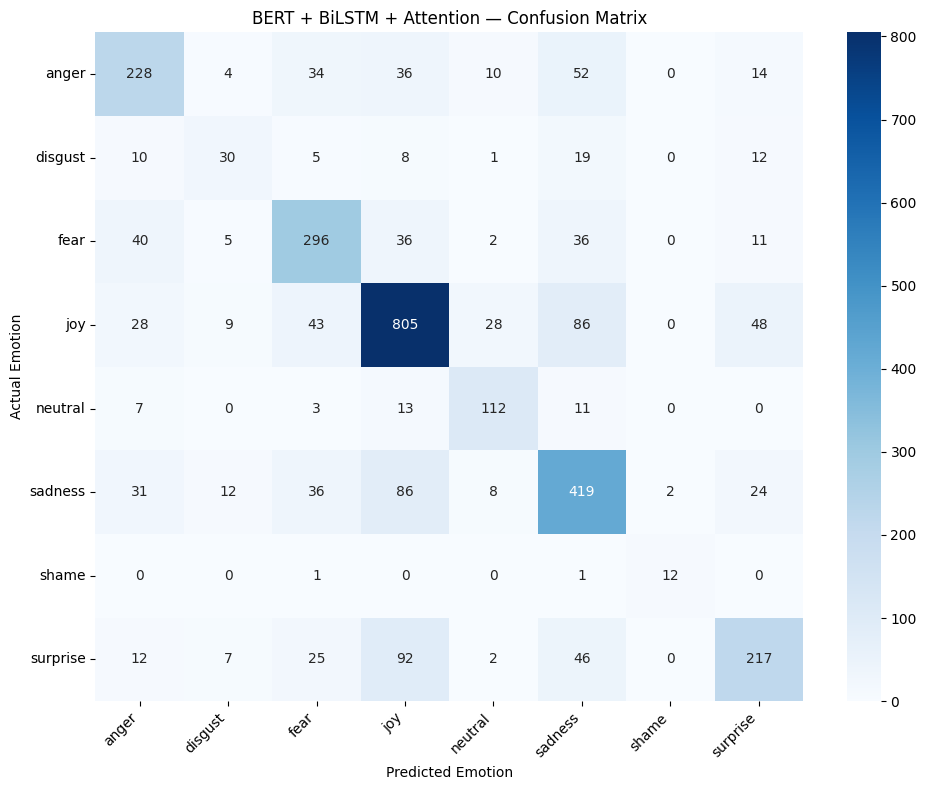

In [29]:

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(num_labels)
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("BERT + BiLSTM + Attention — Confusion Matrix")
plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [30]:

from sklearn.utils.class_weight import compute_class_weight

train_labels = train_df["label"].to_numpy()

classes = np.arange(num_labels)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_labels
)

# Moderate square-root weighting
class_weights = np.sqrt(class_weights)

# Normalize weights
class_weights = class_weights / class_weights.mean()

class_weights_tensor = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=device
)

weight_df = pd.DataFrame({
    "Emotion": label_encoder.classes_,
    "Training Samples": np.bincount(
        train_labels, minlength=num_labels
    ),
    "Class Weight": class_weights
})

display(weight_df.round(3))


,Emotion,Training Samples,Class Weight
0,anger,3020,0.609
1,disgust,684,1.280
2,fear,3410,0.573
3,joy,8371,0.366
4,neutral,1166,0.981
5,sadness,4939,0.476
6,shame,115,3.123
7,surprise,3212,0.591


In [31]:


weighted_model = BERT_BiLSTM_Attention(
    bert_model=bert_encoder,
    hidden_size=256,
    num_classes=num_labels,
    dropout=0.3
).to(device)

# Weighted cross entropy
criterion = nn.CrossEntropyLoss(
    weight=class_weights_tensor
)

optimizer = AdamW(
    filter(
        lambda p: p.requires_grad,
        weighted_model.parameters()
    ),
    lr=1e-3,
    weight_decay=0.01
)

EPOCHS = 10
PATIENCE = 3

total_steps = len(train_loader) * EPOCHS

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(0.1 * total_steps),
    num_training_steps=total_steps
)

print("Fresh weighted model initialized.")
print("Loss: Weighted Cross Entropy")
print("Optimizer: AdamW")
print("Learning rate: 0.001")


Fresh weighted model initialized.
Loss: Weighted Cross Entropy
Optimizer: AdamW
Learning rate: 0.001


In [33]:

weighted_history = []

best_weighted_f1 = 0
best_weighted_state = None
weighted_patience_counter = 0

weighted_start = time.time()

for epoch in range(EPOCHS):

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")

    train_loss, train_f1 = train_one_epoch(
        weighted_model,
        train_loader,
        optimizer,
        scheduler
    )

    val_loss, val_accuracy, val_f1, _, _ = evaluate_model(
        weighted_model,
        val_loader
    )

    weighted_history.append({
        "Epoch": epoch + 1,
        "Training Loss": train_loss,
        "Training Macro F1": train_f1,
        "Validation Loss": val_loss,
        "Validation Accuracy": val_accuracy,
        "Validation Macro F1": val_f1
    })

    print(f"Training Loss: {train_loss:.4f}")
    print(f"Training Macro F1: {train_f1:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_accuracy:.4f}")
    print(f"Validation Macro F1: {val_f1:.4f}")

    if val_f1 > best_weighted_f1:
        best_weighted_f1 = val_f1

        best_weighted_state = copy.deepcopy(
            weighted_model.state_dict()
        )

        weighted_patience_counter = 0

        torch.save(
            best_weighted_state,
            "/content/best_weighted_bert_bilstm_attention.pt"
        )

        print("Best weighted checkpoint saved!")

    else:
        weighted_patience_counter += 1
        print("No validation improvement.")

    if weighted_patience_counter >= PATIENCE:
        print("\nEarly stopping triggered.")
        break

weighted_training_time = time.time() - weighted_start

if best_weighted_state is not None:
    weighted_model.load_state_dict(best_weighted_state)

print("\nWeighted training completed!")
print("Best validation Macro F1:", round(best_weighted_f1, 4))
print(
    "Training time:",
    round(weighted_training_time / 60, 2),
    "minutes"
)

weighted_history_df = pd.DataFrame(weighted_history)

display(weighted_history_df.round(4))



Epoch 1/10
Training Loss: 1.3584
Training Macro F1: 0.4491
Validation Loss: 1.1202
Validation Accuracy: 0.6244
Validation Macro F1: 0.5818
Best weighted checkpoint saved!

Epoch 2/10
Training Loss: 1.0230
Training Macro F1: 0.6267
Validation Loss: 1.0156
Validation Accuracy: 0.6658
Validation Macro F1: 0.6397
Best weighted checkpoint saved!

Epoch 3/10
Training Loss: 0.8704
Training Macro F1: 0.6868
Validation Loss: 0.9252
Validation Accuracy: 0.6787
Validation Macro F1: 0.6864
Best weighted checkpoint saved!

Epoch 4/10
Training Loss: 0.7161
Training Macro F1: 0.7485
Validation Loss: 0.9544
Validation Accuracy: 0.6681
Validation Macro F1: 0.6736
No validation improvement.

Epoch 5/10
Training Loss: 0.5489
Training Macro F1: 0.8153
Validation Loss: 1.0072
Validation Accuracy: 0.6857
Validation Macro F1: 0.6770
No validation improvement.

Epoch 6/10
Training Loss: 0.3846
Training Macro F1: 0.8770
Validation Loss: 1.1004
Validation Accuracy: 0.6925
Validation Macro F1: 0.6842
No validat

,Epoch,Training Loss,Training Macro F1,Validation Loss,Validation Accuracy,Validation Macro F1
0,1,1.3584,0.4491,1.1202,0.6244,0.5818
1,2,1.0230,0.6267,1.0156,0.6658,0.6397
2,3,0.8704,0.6868,0.9252,0.6787,0.6864
3,4,0.7161,0.7485,0.9544,0.6681,0.6736
4,5,0.5489,0.8153,1.0072,0.6857,0.6770
5,6,0.3846,0.8770,1.1004,0.6925,0.6842


In [34]:

original_val = evaluate_model(model, val_loader)
weighted_val = evaluate_model(weighted_model, val_loader)

comparison = pd.DataFrame([
    {
        "Model": "Original BERT-BiLSTM-Attention",
        "Accuracy": original_val[1],
        "Macro F1": original_val[2]
    },
    {
        "Model": "Weighted BERT-BiLSTM-Attention",
        "Accuracy": weighted_val[1],
        "Macro F1": weighted_val[2]
    }
])

display(comparison.round(4))


,Model,Accuracy,Macro F1
0,Original BERT-BiLSTM-Attention,0.6889,0.6805
1,Weighted BERT-BiLSTM-Attention,0.6787,0.6864


In [35]:

from sklearn.metrics import classification_report

# Original model predictions
original_val_result = evaluate_model(model, val_loader)

original_val_true = original_val_result[3]
original_val_pred = original_val_result[4]

# Weighted model predictions
weighted_val_result = evaluate_model(
    weighted_model, val_loader
)

weighted_val_true = weighted_val_result[3]
weighted_val_pred = weighted_val_result[4]

# Generate reports
original_report = classification_report(
    original_val_true,
    original_val_pred,
    labels=np.arange(num_labels),
    target_names=label_encoder.classes_,
    output_dict=True,
    zero_division=0
)

weighted_report = classification_report(
    weighted_val_true,
    weighted_val_pred,
    labels=np.arange(num_labels),
    target_names=label_encoder.classes_,
    output_dict=True,
    zero_division=0
)

# Compare each emotion
class_comparison = []

for emotion in label_encoder.classes_:

    class_comparison.append({
        "Emotion": emotion,

        "Original Precision":
            original_report[emotion]["precision"],

        "Weighted Precision":
            weighted_report[emotion]["precision"],

        "Original Recall":
            original_report[emotion]["recall"],

        "Weighted Recall":
            weighted_report[emotion]["recall"],

        "Original F1":
            original_report[emotion]["f1-score"],

        "Weighted F1":
            weighted_report[emotion]["f1-score"]
    })

class_comparison_df = pd.DataFrame(class_comparison)

display(class_comparison_df.round(4))


,Emotion,Original Precision,Weighted Precision,Original Recall,Weighted Recall,Original F1,Weighted F1
0,anger,0.6481,0.6383,0.6499,0.6366,0.6490,0.6375
1,disgust,0.4557,0.3881,0.4186,0.6047,0.4364,0.4727
2,fear,0.6858,0.7385,0.7019,0.6432,0.6937,0.6876
3,joy,0.7511,0.7955,0.7820,0.7027,0.7663,0.7462
4,neutral,0.6970,0.6205,0.7877,0.8288,0.7395,0.7097
5,sadness,0.6542,0.7200,0.6807,0.6418,0.6672,0.6787
6,shame,0.9333,0.9375,0.9333,1.0000,0.9333,0.9677
7,surprise,0.6399,0.5118,0.4950,0.6990,0.5582,0.5910


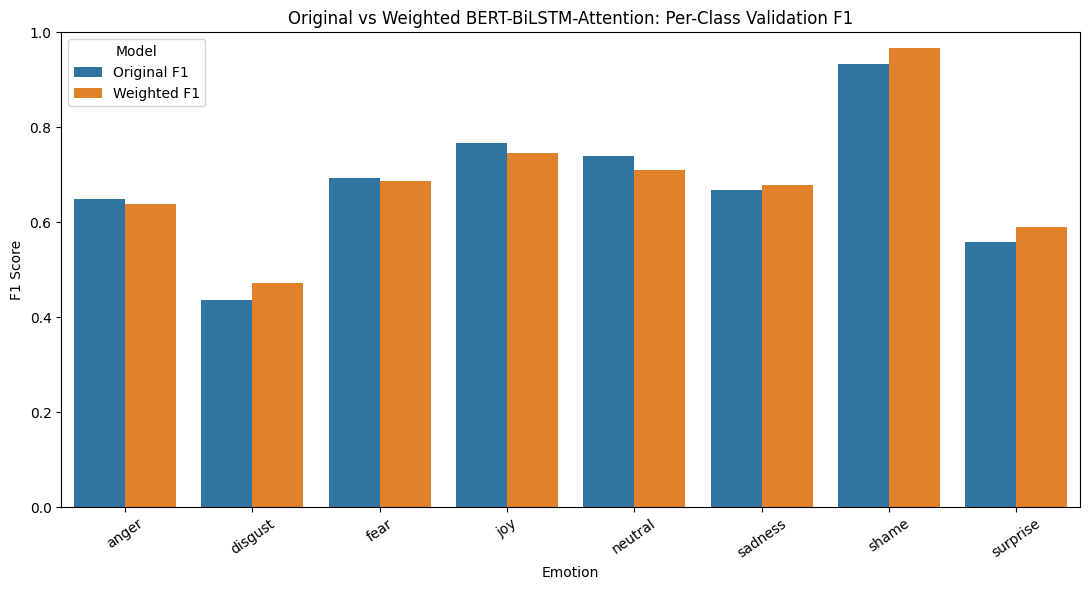

In [36]:

plot_df = class_comparison_df[
    ["Emotion", "Original F1", "Weighted F1"]
].melt(
    id_vars="Emotion",
    var_name="Model",
    value_name="F1 Score"
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=plot_df,
    x="Emotion",
    y="F1 Score",
    hue="Model"
)

plt.title(
    "Original vs Weighted BERT-BiLSTM-Attention: "
    "Per-Class Validation F1"
)

plt.ylim(0, 1)
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()


In [37]:

weighted_model.load_state_dict(
    torch.load(
        "/content/best_weighted_bert_bilstm_attention.pt",
        map_location=device,
        weights_only=True
    )
)

weighted_model.eval()

(
    weighted_test_loss,
    weighted_test_accuracy,
    weighted_test_f1,
    weighted_y_true,
    weighted_y_pred
) = evaluate_model(weighted_model, test_loader)

weighted_test_precision = precision_score(
    weighted_y_true,
    weighted_y_pred,
    average="macro",
    zero_division=0
)

weighted_test_recall = recall_score(
    weighted_y_true,
    weighted_y_pred,
    average="macro",
    zero_division=0
)

print("WEIGHTED BERT + BiLSTM + ATTENTION")
print("-----------------------------------")
print("Test Accuracy:", round(weighted_test_accuracy, 4))
print("Macro Precision:", round(weighted_test_precision, 4))
print("Macro Recall:", round(weighted_test_recall, 4))
print("Macro F1:", round(weighted_test_f1, 4))

print("\nClassification Report:\n")

print(classification_report(
    weighted_y_true,
    weighted_y_pred,
    labels=np.arange(num_labels),
    target_names=label_encoder.classes_,
    zero_division=0
))


WEIGHTED BERT + BiLSTM + ATTENTION
-----------------------------------
Test Accuracy: 0.6565
Macro Precision: 0.6432
Macro Recall: 0.6878
Macro F1: 0.6594

Classification Report:

              precision    recall  f1-score   support

       anger       0.61      0.64      0.63       378
     disgust       0.35      0.42      0.38        85
        fear       0.71      0.62      0.66       426
         joy       0.80      0.68      0.74      1047
     neutral       0.60      0.85      0.70       146
     sadness       0.66      0.62      0.64       618
       shame       0.93      1.00      0.97        14
    surprise       0.49      0.67      0.57       401

    accuracy                           0.66      3115
   macro avg       0.64      0.69      0.66      3115
weighted avg       0.68      0.66      0.66      3115



In [38]:


original_test_report = classification_report(
    y_true,
    y_pred,
    labels=np.arange(num_labels),
    target_names=label_encoder.classes_,
    output_dict=True,
    zero_division=0
)

weighted_test_report = classification_report(
    weighted_y_true,
    weighted_y_pred,
    labels=np.arange(num_labels),
    target_names=label_encoder.classes_,
    output_dict=True,
    zero_division=0
)

test_comparison = pd.DataFrame([
    {
        "Model": "Original BERT-BiLSTM-Attention",
        "Accuracy": test_accuracy,
        "Macro Precision": test_macro_precision,
        "Macro Recall": test_macro_recall,
        "Macro F1": test_macro_f1,
        "Disgust F1": original_test_report["disgust"]["f1-score"]
    },
    {
        "Model": "Weighted BERT-BiLSTM-Attention",
        "Accuracy": weighted_test_accuracy,
        "Macro Precision": weighted_test_precision,
        "Macro Recall": weighted_test_recall,
        "Macro F1": weighted_test_f1,
        "Disgust F1": weighted_test_report["disgust"]["f1-score"]
    }
])

display(test_comparison.round(4))

original_test_report = classification_report(
    y_true,
    y_pred,
    labels=np.arange(num_labels),
    target_names=label_encoder.classes_,
    output_dict=True,
    zero_division=0
)

weighted_test_report = classification_report(
    weighted_y_true,
    weighted_y_pred,
    labels=np.arange(num_labels),
    target_names=label_encoder.classes_,
    output_dict=True,
    zero_division=0
)

test_comparison = pd.DataFrame([
    {
        "Model": "Original BERT-BiLSTM-Attention",
        "Accuracy": test_accuracy,
        "Macro Precision": test_macro_precision,
        "Macro Recall": test_macro_recall,
        "Macro F1": test_macro_f1,
        "Disgust F1": original_test_report["disgust"]["f1-score"]
    },
    {
        "Model": "Weighted BERT-BiLSTM-Attention",
        "Accuracy": weighted_test_accuracy,
        "Macro Precision": weighted_test_precision,
        "Macro Recall": weighted_test_recall,
        "Macro F1": weighted_test_f1,
        "Disgust F1": weighted_test_report["disgust"]["f1-score"]
    }
])

display(test_comparison.round(4))


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Disgust F1
0,Original BERT-BiLSTM-Attention,0.6803,0.6675,0.6579,0.6607,0.3947
1,Weighted BERT-BiLSTM-Attention,0.6565,0.6432,0.6878,0.6594,0.3810


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Disgust F1
0,Original BERT-BiLSTM-Attention,0.6803,0.6675,0.6579,0.6607,0.3947
1,Weighted BERT-BiLSTM-Attention,0.6565,0.6432,0.6878,0.6594,0.3810


In [39]:

DISTILBERT_NAME = "distilbert-base-uncased"

distil_tokenizer = AutoTokenizer.from_pretrained(
    DISTILBERT_NAME
)

distil_encoder = AutoModel.from_pretrained(
    DISTILBERT_NAME
)

distil_encoder = distil_encoder.to(device)

# Freeze DistilBERT for the first experiment
for param in distil_encoder.parameters():
    param.requires_grad = False

distil_encoder.eval()

print("DistilBERT loaded successfully!")
print("Hidden size:", distil_encoder.config.dim)
print("Transformer layers:", distil_encoder.config.n_layers)
print("Vocabulary size:", distil_tokenizer.vocab_size)
print("Device:", device)


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


DistilBERT loaded successfully!
Hidden size: 768
Transformer layers: 6
Vocabulary size: 30522
Device: cuda


In [40]:

MAX_LENGTH = 128

def distil_tokenize_texts(texts):
    return distil_tokenizer(
        texts.tolist(),
        max_length=MAX_LENGTH,
        padding="max_length",
        truncation=True,
        return_attention_mask=True,
        return_tensors="pt"
    )

distil_train_encodings = distil_tokenize_texts(
    train_df["Text"]
)

distil_val_encodings = distil_tokenize_texts(
    val_df["Text"]
)

distil_test_encodings = distil_tokenize_texts(
    test_df["Text"]
)

print("Training shape:",
      distil_train_encodings["input_ids"].shape)

print("Validation shape:",
      distil_val_encodings["input_ids"].shape)

print("Testing shape:",
      distil_test_encodings["input_ids"].shape)


Training shape: torch.Size([24917, 128])
Validation shape: torch.Size([3115, 128])
Testing shape: torch.Size([3115, 128])


In [41]:

distil_train_dataset = EmotionDataset(
    distil_train_encodings,
    train_df["label"]
)

distil_val_dataset = EmotionDataset(
    distil_val_encodings,
    val_df["label"]
)

distil_test_dataset = EmotionDataset(
    distil_test_encodings,
    test_df["label"]
)

print("Training samples:", len(distil_train_dataset))
print("Validation samples:", len(distil_val_dataset))
print("Testing samples:", len(distil_test_dataset))


Training samples: 24917
Validation samples: 3115
Testing samples: 3115


In [42]:

BATCH_SIZE = 16

distil_train_loader = DataLoader(
    distil_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

distil_val_loader = DataLoader(
    distil_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

distil_test_loader = DataLoader(
    distil_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Training batches:", len(distil_train_loader))
print("Validation batches:", len(distil_val_loader))
print("Testing batches:", len(distil_test_loader))


Training batches: 1558
Validation batches: 195
Testing batches: 195


In [43]:

distil_model = BERT_BiLSTM_Attention(
    bert_model=distil_encoder,
    hidden_size=256,
    num_classes=num_labels,
    dropout=0.3
).to(device)

print(distil_model)

total_params = sum(
    p.numel()
    for p in distil_model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in distil_model.parameters()
    if p.requires_grad
)

print("\nTotal parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")


BERT_BiLSTM_Attention(
  (bert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSelfAttention(
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
          (ffn): FFN(
            (dropout): Dropout(p=0.1, inplace=False

In [44]:

batch = next(iter(distil_train_loader))

input_ids = batch["input_ids"].to(device)
attention_mask = batch["attention_mask"].to(device)

distil_model.eval()

with torch.no_grad():
    outputs = distil_model(
        input_ids=input_ids,
        attention_mask=attention_mask
    )

print("Input shape:", input_ids.shape)
print("Output shape:", outputs.shape)

assert outputs.shape == (BATCH_SIZE, num_labels)

print("\nDistilBERT forward pass successful!")


Input shape: torch.Size([16, 128])
Output shape: torch.Size([16, 8])

DistilBERT forward pass successful!


In [45]:

EPOCHS = 10
LEARNING_RATE = 1e-3
PATIENCE = 3

# Reset to ordinary, unweighted cross-entropy
criterion = nn.CrossEntropyLoss()

# Fresh optimizer
distil_optimizer = AdamW(
    filter(
        lambda p: p.requires_grad,
        distil_model.parameters()
    ),
    lr=LEARNING_RATE,
    weight_decay=0.01
)

total_steps = len(distil_train_loader) * EPOCHS

distil_scheduler = get_linear_schedule_with_warmup(
    distil_optimizer,
    num_warmup_steps=int(0.1 * total_steps),
    num_training_steps=total_steps
)

print("Loss: CrossEntropyLoss")
print("Optimizer: AdamW")
print("Learning rate:", LEARNING_RATE)
print("Epochs:", EPOCHS)
print("Early stopping patience:", PATIENCE)


Loss: CrossEntropyLoss
Optimizer: AdamW
Learning rate: 0.001
Epochs: 10
Early stopping patience: 3


In [46]:

distil_history = []

best_distil_f1 = -1
best_distil_state = None
distil_patience_counter = 0

distil_training_start = time.time()

for epoch in range(EPOCHS):

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")

    # Training
    train_loss, train_f1 = train_one_epoch(
        distil_model,
        distil_train_loader,
        distil_optimizer,
        distil_scheduler
    )

    # Validation
    val_loss, val_accuracy, val_f1, _, _ = evaluate_model(
        distil_model,
        distil_val_loader
    )

    distil_history.append({
        "Epoch": epoch + 1,
        "Training Loss": train_loss,
        "Training Macro F1": train_f1,
        "Validation Loss": val_loss,
        "Validation Accuracy": val_accuracy,
        "Validation Macro F1": val_f1
    })

    print(f"Training Loss: {train_loss:.4f}")
    print(f"Training Macro F1: {train_f1:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_accuracy:.4f}")
    print(f"Validation Macro F1: {val_f1:.4f}")

    # Save best checkpoint
    if val_f1 > best_distil_f1:

        best_distil_f1 = val_f1

        best_distil_state = copy.deepcopy(
            distil_model.state_dict()
        )

        distil_patience_counter = 0

        torch.save(
            best_distil_state,
            "/content/best_distilbert_bilstm_attention.pt"
        )

        print("Best DistilBERT checkpoint saved!")

    else:
        distil_patience_counter += 1
        print("No validation improvement.")

    # Early stopping
    if distil_patience_counter >= PATIENCE:
        print("\nEarly stopping triggered.")
        break

distil_training_time = time.time() - distil_training_start

# Restore best checkpoint
if best_distil_state is not None:
    distil_model.load_state_dict(best_distil_state)

print("\nDistilBERT training completed!")
print("Best validation Macro F1:", round(best_distil_f1, 4))
print(
    "Training time:",
    round(distil_training_time / 60, 2),
    "minutes"
)

distil_history_df = pd.DataFrame(distil_history)

display(distil_history_df.round(4))



Epoch 1/10
Training Loss: 1.3069
Training Macro F1: 0.3787
Validation Loss: 1.0926
Validation Accuracy: 0.6035
Validation Macro F1: 0.5337
Best DistilBERT checkpoint saved!

Epoch 2/10
Training Loss: 1.0255
Training Macro F1: 0.5941
Validation Loss: 0.9762
Validation Accuracy: 0.6465
Validation Macro F1: 0.6382
Best DistilBERT checkpoint saved!

Epoch 3/10
Training Loss: 0.9012
Training Macro F1: 0.6620
Validation Loss: 0.9498
Validation Accuracy: 0.6626
Validation Macro F1: 0.6462
Best DistilBERT checkpoint saved!

Epoch 4/10
Training Loss: 0.7963
Training Macro F1: 0.7077
Validation Loss: 0.9069
Validation Accuracy: 0.6809
Validation Macro F1: 0.6602
Best DistilBERT checkpoint saved!

Epoch 5/10
Training Loss: 0.6883
Training Macro F1: 0.7508
Validation Loss: 0.9125
Validation Accuracy: 0.6931
Validation Macro F1: 0.6735
Best DistilBERT checkpoint saved!

Epoch 6/10
Training Loss: 0.5678
Training Macro F1: 0.7978
Validation Loss: 0.9512
Validation Accuracy: 0.6844
Validation Macro F

,Epoch,Training Loss,Training Macro F1,Validation Loss,Validation Accuracy,Validation Macro F1
0,1,1.3069,0.3787,1.0926,0.6035,0.5337
1,2,1.0255,0.5941,0.9762,0.6465,0.6382
2,3,0.9012,0.6620,0.9498,0.6626,0.6462
3,4,0.7963,0.7077,0.9069,0.6809,0.6602
4,5,0.6883,0.7508,0.9125,0.6931,0.6735
5,6,0.5678,0.7978,0.9512,0.6844,0.6699
6,7,0.4386,0.8444,1.0171,0.6822,0.6739
7,8,0.3220,0.8910,1.1089,0.6729,0.6696
8,9,0.2223,0.9297,1.2116,0.6770,0.6636
9,10,0.1561,0.9531,1.2642,0.6732,0.6631


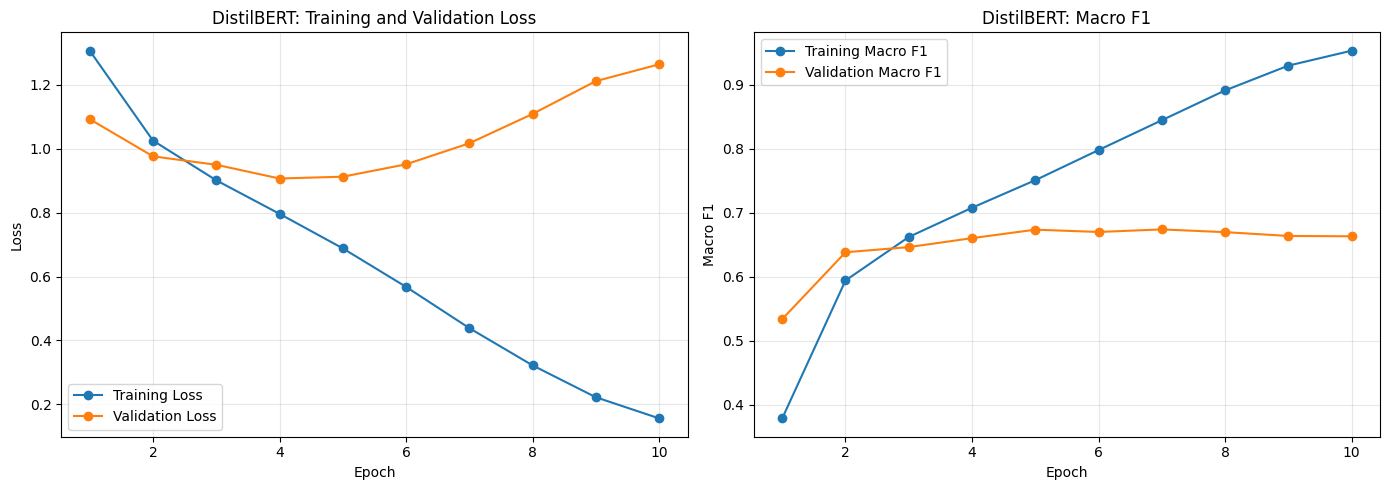

In [47]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss curves
axes[0].plot(
    distil_history_df["Epoch"],
    distil_history_df["Training Loss"],
    marker="o",
    label="Training Loss"
)

axes[0].plot(
    distil_history_df["Epoch"],
    distil_history_df["Validation Loss"],
    marker="o",
    label="Validation Loss"
)

axes[0].set_title("DistilBERT: Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Macro F1 curves
axes[1].plot(
    distil_history_df["Epoch"],
    distil_history_df["Training Macro F1"],
    marker="o",
    label="Training Macro F1"
)

axes[1].plot(
    distil_history_df["Epoch"],
    distil_history_df["Validation Macro F1"],
    marker="o",
    label="Validation Macro F1"
)

axes[1].set_title("DistilBERT: Macro F1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Macro F1")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [61]:

distil_best_state = torch.load(
    "/content/best_distilbert_bilstm_attention.pt",
    map_location=device,
    weights_only=True
)

distil_model.load_state_dict(distil_best_state)
distil_model.eval()

(
    distil_test_loss,
    distil_test_accuracy,
    distil_test_f1,
    distil_y_true,
    distil_y_pred
) = evaluate_model(
    distil_model,
    distil_test_loader
)

distil_test_precision = precision_score(
    distil_y_true,
    distil_y_pred,
    average="macro",
    zero_division=0
)

distil_test_recall = recall_score(
    distil_y_true,
    distil_y_pred,
    average="macro",
    zero_division=0
)

print("DISTILBERT + BiLSTM + ATTENTION")
print("--------------------------------")
print("Test Loss:", round(distil_test_loss, 4))
print("Accuracy:", round(distil_test_accuracy, 4))
print("Macro Precision:", round(distil_test_precision, 4))
print("Macro Recall:", round(distil_test_recall, 4))
print("Macro F1:", round(distil_test_f1, 4))

print("\nClassification Report:\n")

print(classification_report(
    distil_y_true,
    distil_y_pred,
    labels=np.arange(num_labels),
    target_names=label_encoder.classes_,
    zero_division=0
))


DISTILBERT + BiLSTM + ATTENTION
--------------------------------
Test Loss: 1.0695
Accuracy: 0.678
Macro Precision: 0.6873
Macro Recall: 0.634
Macro F1: 0.654

Classification Report:

              precision    recall  f1-score   support

       anger       0.65      0.54      0.59       378
     disgust       0.47      0.24      0.31        85
        fear       0.67      0.67      0.67       426
         joy       0.74      0.80      0.77      1047
     neutral       0.73      0.73      0.73       146
     sadness       0.62      0.68      0.65       618
       shame       1.00      0.86      0.92        14
    surprise       0.62      0.56      0.59       401

    accuracy                           0.68      3115
   macro avg       0.69      0.63      0.65      3115
weighted avg       0.67      0.68      0.67      3115



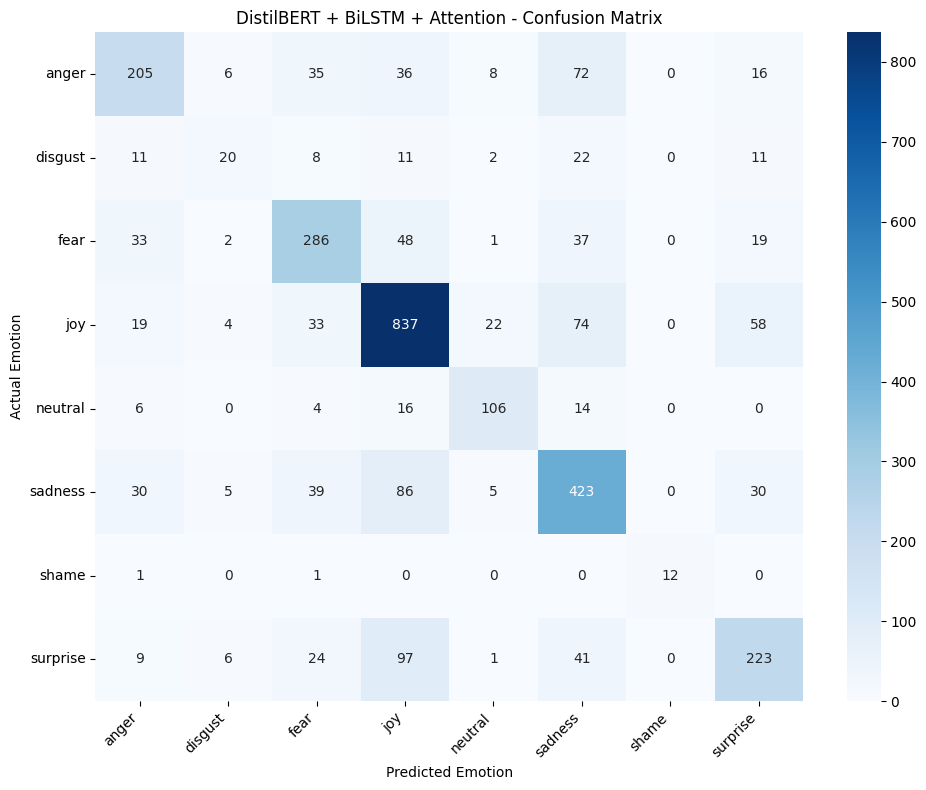

In [49]:

distil_cm = confusion_matrix(
    distil_y_true,
    distil_y_pred,
    labels=np.arange(num_labels)
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    distil_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("DistilBERT + BiLSTM + Attention - Confusion Matrix")
plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [50]:

regularized_distil_model = BERT_BiLSTM_Attention(
    bert_model=distil_encoder,
    hidden_size=256,
    num_classes=num_labels,
    dropout=0.5
).to(device)

# Ordinary loss, no class weighting
criterion = nn.CrossEntropyLoss()

regularized_optimizer = AdamW(
    filter(
        lambda p: p.requires_grad,
        regularized_distil_model.parameters()
    ),
    lr=5e-4,
    weight_decay=0.05
)

EPOCHS = 10
PATIENCE = 3

total_steps = len(distil_train_loader) * EPOCHS

regularized_scheduler = get_linear_schedule_with_warmup(
    regularized_optimizer,
    num_warmup_steps=int(0.1 * total_steps),
    num_training_steps=total_steps
)

print("Regularized DistilBERT initialized!")
print("Dropout: 0.5")
print("Learning rate: 0.0005")
print("Weight decay: 0.05")
print("Loss: CrossEntropyLoss")


Regularized DistilBERT initialized!
Dropout: 0.5
Learning rate: 0.0005
Weight decay: 0.05
Loss: CrossEntropyLoss


In [51]:

regularized_history = []

best_regularized_f1 = -1
best_regularized_state = None
regularized_patience_counter = 0

regularized_start = time.time()

for epoch in range(EPOCHS):

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")

    # Training
    train_loss, train_f1 = train_one_epoch(
        regularized_distil_model,
        distil_train_loader,
        regularized_optimizer,
        regularized_scheduler
    )

    # Validation
    val_loss, val_accuracy, val_f1, _, _ = evaluate_model(
        regularized_distil_model,
        distil_val_loader
    )

    regularized_history.append({
        "Epoch": epoch + 1,
        "Training Loss": train_loss,
        "Training Macro F1": train_f1,
        "Validation Loss": val_loss,
        "Validation Accuracy": val_accuracy,
        "Validation Macro F1": val_f1
    })

    print(f"Training Loss: {train_loss:.4f}")
    print(f"Training Macro F1: {train_f1:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_accuracy:.4f}")
    print(f"Validation Macro F1: {val_f1:.4f}")

    # Save best model
    if val_f1 > best_regularized_f1:

        best_regularized_f1 = val_f1

        best_regularized_state = copy.deepcopy(
            regularized_distil_model.state_dict()
        )

        regularized_patience_counter = 0

        torch.save(
            best_regularized_state,
            "/content/best_regularized_distilbert.pt"
        )

        print("Best checkpoint saved!")

    else:
        regularized_patience_counter += 1
        print("No validation improvement.")

    # Early stopping
    if regularized_patience_counter >= PATIENCE:
        print("\nEarly stopping triggered.")
        break

regularized_training_time = time.time() - regularized_start

# Restore best checkpoint
if best_regularized_state is not None:
    regularized_distil_model.load_state_dict(
        best_regularized_state
    )

regularized_history_df = pd.DataFrame(
    regularized_history
)

print("\nTraining completed!")
print(
    "Best Validation Macro F1:",
    round(best_regularized_f1, 4)
)

print(
    "Training Time:",
    round(regularized_training_time / 60, 2),
    "minutes"
)

display(regularized_history_df.round(4))



Epoch 1/10
Training Loss: 1.3789
Training Macro F1: 0.3452
Validation Loss: 1.1498
Validation Accuracy: 0.5987
Validation Macro F1: 0.4761
Best checkpoint saved!

Epoch 2/10
Training Loss: 1.0769
Training Macro F1: 0.5400
Validation Loss: 0.9904
Validation Accuracy: 0.6488
Validation Macro F1: 0.6131
Best checkpoint saved!

Epoch 3/10
Training Loss: 0.9515
Training Macro F1: 0.6365
Validation Loss: 0.9555
Validation Accuracy: 0.6600
Validation Macro F1: 0.6450
Best checkpoint saved!

Epoch 4/10
Training Loss: 0.8702
Training Macro F1: 0.6718
Validation Loss: 0.9220
Validation Accuracy: 0.6735
Validation Macro F1: 0.6474
Best checkpoint saved!

Epoch 5/10
Training Loss: 0.7935
Training Macro F1: 0.7076
Validation Loss: 0.9123
Validation Accuracy: 0.6754
Validation Macro F1: 0.6545
Best checkpoint saved!

Epoch 6/10
Training Loss: 0.7167
Training Macro F1: 0.7353
Validation Loss: 0.9053
Validation Accuracy: 0.6787
Validation Macro F1: 0.6667
Best checkpoint saved!

Epoch 7/10
Training L

,Epoch,Training Loss,Training Macro F1,Validation Loss,Validation Accuracy,Validation Macro F1
0,1,1.3789,0.3452,1.1498,0.5987,0.4761
1,2,1.0769,0.5400,0.9904,0.6488,0.6131
2,3,0.9515,0.6365,0.9555,0.6600,0.6450
3,4,0.8702,0.6718,0.9220,0.6735,0.6474
4,5,0.7935,0.7076,0.9123,0.6754,0.6545
5,6,0.7167,0.7353,0.9053,0.6787,0.6667
6,7,0.6321,0.7729,0.9347,0.6700,0.6506
7,8,0.5532,0.8050,0.9730,0.6790,0.6503
8,9,0.4681,0.8386,1.0132,0.6751,0.6557


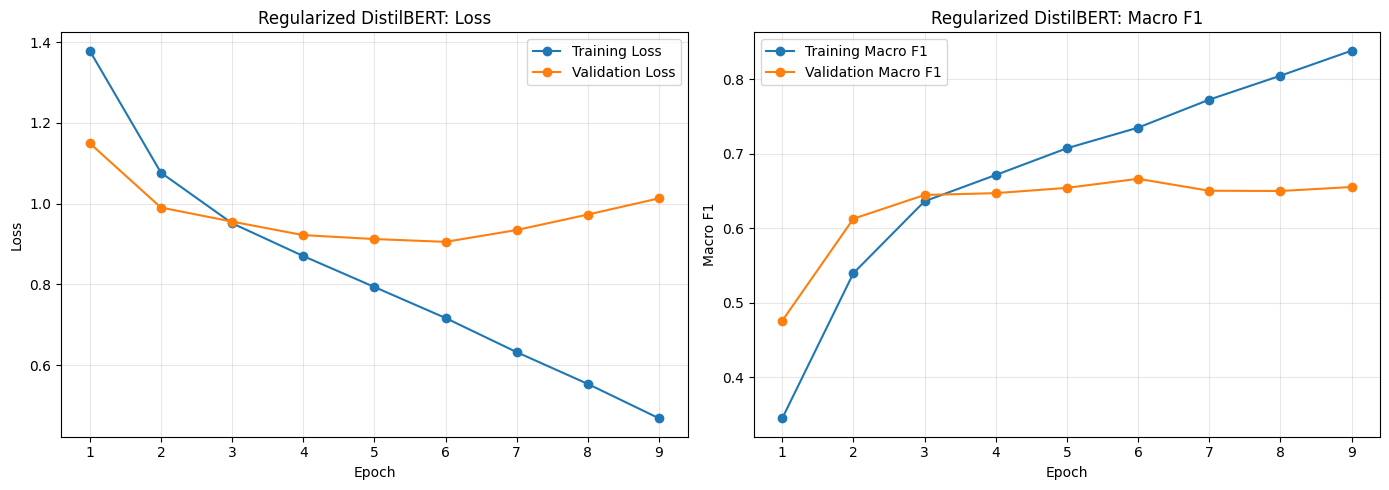

In [52]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss
axes[0].plot(
    regularized_history_df["Epoch"],
    regularized_history_df["Training Loss"],
    marker="o",
    label="Training Loss"
)

axes[0].plot(
    regularized_history_df["Epoch"],
    regularized_history_df["Validation Loss"],
    marker="o",
    label="Validation Loss"
)

axes[0].set_title("Regularized DistilBERT: Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Macro F1
axes[1].plot(
    regularized_history_df["Epoch"],
    regularized_history_df["Training Macro F1"],
    marker="o",
    label="Training Macro F1"
)

axes[1].plot(
    regularized_history_df["Epoch"],
    regularized_history_df["Validation Macro F1"],
    marker="o",
    label="Validation Macro F1"
)

axes[1].set_title("Regularized DistilBERT: Macro F1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Macro F1")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [53]:

# ============================================
# STEP 32: PARTIAL DISTILBERT FINE-TUNING
# ============================================

# Load a fresh pretrained encoder
fresh_distil_encoder = AutoModel.from_pretrained(
    "distilbert-base-uncased"
).to(device)

# Freeze all DistilBERT parameters
for param in fresh_distil_encoder.parameters():
    param.requires_grad = False

# Unfreeze the final two transformer layers
for layer in fresh_distil_encoder.transformer.layer[-2:]:
    for param in layer.parameters():
        param.requires_grad = True

# Unfreeze final LayerNorm
for param in fresh_distil_encoder.transformer.layer[-1].output_layer_norm.parameters():
    param.requires_grad = True

# Build fresh hybrid model
finetuned_distil_model = BERT_BiLSTM_Attention(
    bert_model=fresh_distil_encoder,
    hidden_size=256,
    num_classes=num_labels,
    dropout=0.3
).to(device)

# Unfreeze BiLSTM, attention and classifier
for module in [
    finetuned_distil_model.lstm,
    finetuned_distil_model.attention,
    finetuned_distil_model.classifier
]:
    for param in module.parameters():
        param.requires_grad = True

# Count parameters
total_params = sum(
    p.numel() for p in finetuned_distil_model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in finetuned_distil_model.parameters()
    if p.requires_grad
)

print("Partial fine-tuning model initialized!")
print("Total parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")

print("\nTrainable DistilBERT layers:")
print("Final 2 transformer layers")
print("Earlier 4 transformer layers remain frozen.")


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Partial fine-tuning model initialized!
Total parameters: 68,468,745
Trainable parameters: 16,281,609

Trainable DistilBERT layers:
Final 2 transformer layers
Earlier 4 transformer layers remain frozen.


In [54]:
class DistilBERT_BiLSTM_Attention_FT(nn.Module):

    def __init__(
        self,
        bert_model,
        hidden_size=256,
        num_classes=8,
        dropout=0.3
    ):
        super().__init__()

        self.bert = bert_model

        self.lstm = nn.LSTM(
            input_size=768,
            hidden_size=hidden_size,
            num_layers=1,
            batch_first=True,
            bidirectional=True
        )

        self.attention = nn.Linear(
            hidden_size * 2, 1
        )

        self.dropout = nn.Dropout(dropout)

        self.classifier = nn.Linear(
            hidden_size * 2,
            num_classes
        )

    def forward(self, input_ids, attention_mask):

        # IMPORTANT: No torch.no_grad() here
        bert_outputs = self.bert(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        sequence_output = bert_outputs.last_hidden_state

        lstm_output, _ = self.lstm(sequence_output)

        attention_scores = self.attention(
            lstm_output
        ).squeeze(-1)

        attention_scores = attention_scores.masked_fill(
            attention_mask == 0,
            -1e9
        )

        attention_weights = torch.softmax(
            attention_scores,
            dim=1
        )

        context_vector = torch.sum(
            lstm_output * attention_weights.unsqueeze(-1),
            dim=1
        )

        context_vector = self.dropout(context_vector)

        logits = self.classifier(context_vector)

        return logits


# Initialize using the partially unfrozen encoder
finetuned_distil_model = DistilBERT_BiLSTM_Attention_FT(
    bert_model=fresh_distil_encoder,
    hidden_size=256,
    num_classes=num_labels,
    dropout=0.3
).to(device)

print("Gradient-enabled model initialized!")


Gradient-enabled model initialized!


In [55]:
bert_parameters = [
    p for p in finetuned_distil_model.bert.parameters()
    if p.requires_grad
]

classifier_parameters = (
    list(finetuned_distil_model.lstm.parameters()) +
    list(finetuned_distil_model.attention.parameters()) +
    list(finetuned_distil_model.classifier.parameters())
)

finetune_optimizer = AdamW(
    [
        {
            "params": bert_parameters,
            "lr": 2e-5
        },
        {
            "params": classifier_parameters,
            "lr": 5e-4
        }
    ],
    weight_decay=0.01
)

criterion = nn.CrossEntropyLoss()

EPOCHS = 10
PATIENCE = 3

total_steps = len(distil_train_loader) * EPOCHS

finetune_scheduler = get_linear_schedule_with_warmup(
    finetune_optimizer,
    num_warmup_steps=int(0.1 * total_steps),
    num_training_steps=total_steps
)

print("DistilBERT learning rate: 2e-5")
print("BiLSTM and classifier learning rate: 5e-4")
print("Loss: CrossEntropyLoss")
print("Optimizer: AdamW")


DistilBERT learning rate: 2e-5
BiLSTM and classifier learning rate: 5e-4
Loss: CrossEntropyLoss
Optimizer: AdamW


In [56]:

finetuned_distil_model.train()

batch = next(iter(distil_train_loader))

input_ids = batch["input_ids"].to(device)
attention_mask = batch["attention_mask"].to(device)
labels = batch["labels"].to(device)

finetune_optimizer.zero_grad()

outputs = finetuned_distil_model(
    input_ids=input_ids,
    attention_mask=attention_mask
)

loss = criterion(outputs, labels)
loss.backward()

# Check an unfrozen transformer layer
unfrozen_grad = (
    finetuned_distil_model
    .bert.transformer.layer[-1]
    .ffn.lin1.weight.grad
)

# Check a frozen transformer layer
frozen_grad = (
    finetuned_distil_model
    .bert.transformer.layer[0]
    .ffn.lin1.weight.grad
)

print("Output shape:", outputs.shape)
print("Loss:", round(loss.item(), 4))

print(
    "Unfrozen layer gradient:",
    unfrozen_grad is not None
)

print(
    "Frozen layer gradient:",
    frozen_grad is not None
)

assert unfrozen_grad is not None
assert frozen_grad is None

finetune_optimizer.zero_grad()

print("\nGradient verification successful!")


Output shape: torch.Size([16, 8])
Loss: 2.0678
Unfrozen layer gradient: True
Frozen layer gradient: False

Gradient verification successful!


In [58]:

def train_finetuned_epoch(
    model,
    loader,
    optimizer,
    scheduler
):
    model.train()

    total_loss = 0
    all_preds = []
    all_labels = []

    for batch in loader:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        loss = criterion(outputs, labels)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            filter(
                lambda p: p.requires_grad,
                model.parameters()
            ),
            max_norm=1.0
        )

        optimizer.step()
        scheduler.step()

        total_loss += loss.item()

        predictions = torch.argmax(outputs, dim=1)

        all_preds.extend(predictions.detach().cpu().numpy())
        all_labels.extend(labels.detach().cpu().numpy())

    avg_loss = total_loss / len(loader)

    macro_f1 = f1_score(
        all_labels,
        all_preds,
        average="macro",
        zero_division=0
    )

    return avg_loss, macro_f1


In [59]:

finetune_history = []

best_finetune_f1 = -1
best_finetune_state = None
finetune_patience_counter = 0

finetune_start = time.time()

for epoch in range(EPOCHS):

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")

    # Train
    train_loss, train_f1 = train_finetuned_epoch(
        finetuned_distil_model,
        distil_train_loader,
        finetune_optimizer,
        finetune_scheduler
    )

    # Validate
    val_loss, val_accuracy, val_f1, _, _ = evaluate_model(
        finetuned_distil_model,
        distil_val_loader
    )

    finetune_history.append({
        "Epoch": epoch + 1,
        "Training Loss": train_loss,
        "Training Macro F1": train_f1,
        "Validation Loss": val_loss,
        "Validation Accuracy": val_accuracy,
        "Validation Macro F1": val_f1
    })

    print(f"Training Loss: {train_loss:.4f}")
    print(f"Training Macro F1: {train_f1:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_accuracy:.4f}")
    print(f"Validation Macro F1: {val_f1:.4f}")

    # Save best checkpoint
    if val_f1 > best_finetune_f1:

        best_finetune_f1 = val_f1

        best_finetune_state = copy.deepcopy(
            finetuned_distil_model.state_dict()
        )

        finetune_patience_counter = 0

        torch.save(
            best_finetune_state,
            "/content/best_finetuned_distilbert.pt"
        )

        print("Best fine-tuned checkpoint saved!")

    else:
        finetune_patience_counter += 1
        print("No validation improvement.")

    # Early stopping
    if finetune_patience_counter >= PATIENCE:
        print("\nEarly stopping triggered.")
        break

finetune_training_time = time.time() - finetune_start

# Restore best checkpoint
if best_finetune_state is not None:
    finetuned_distil_model.load_state_dict(
        best_finetune_state
    )

finetune_history_df = pd.DataFrame(finetune_history)

print("\nPartial fine-tuning completed!")
print("Best Validation Macro F1:", round(best_finetune_f1, 4))

print(
    "Training Time:",
    round(finetune_training_time / 60, 2),
    "minutes"
)

display(finetune_history_df.round(4))



Epoch 1/10
Training Loss: 1.2817
Training Macro F1: 0.4071
Validation Loss: 1.0441
Validation Accuracy: 0.6212
Validation Macro F1: 0.5816
Best fine-tuned checkpoint saved!

Epoch 2/10
Training Loss: 0.9585
Training Macro F1: 0.6250
Validation Loss: 0.9180
Validation Accuracy: 0.6706
Validation Macro F1: 0.6478
Best fine-tuned checkpoint saved!

Epoch 3/10
Training Loss: 0.8102
Training Macro F1: 0.6959
Validation Loss: 0.8925
Validation Accuracy: 0.6870
Validation Macro F1: 0.6622
Best fine-tuned checkpoint saved!

Epoch 4/10
Training Loss: 0.6732
Training Macro F1: 0.7526
Validation Loss: 0.9297
Validation Accuracy: 0.6831
Validation Macro F1: 0.6577
No validation improvement.

Epoch 5/10
Training Loss: 0.5332
Training Macro F1: 0.8124
Validation Loss: 0.9854
Validation Accuracy: 0.6905
Validation Macro F1: 0.6682
Best fine-tuned checkpoint saved!

Epoch 6/10
Training Loss: 0.3904
Training Macro F1: 0.8639
Validation Loss: 1.0857
Validation Accuracy: 0.6921
Validation Macro F1: 0.67

,Epoch,Training Loss,Training Macro F1,Validation Loss,Validation Accuracy,Validation Macro F1
0,1,1.2817,0.4071,1.0441,0.6212,0.5816
1,2,0.9585,0.6250,0.9180,0.6706,0.6478
2,3,0.8102,0.6959,0.8925,0.6870,0.6622
3,4,0.6732,0.7526,0.9297,0.6831,0.6577
4,5,0.5332,0.8124,0.9854,0.6905,0.6682
5,6,0.3904,0.8639,1.0857,0.6921,0.6715
6,7,0.2745,0.9091,1.2561,0.6902,0.6766
7,8,0.1873,0.9373,1.4098,0.6899,0.6825
8,9,0.1302,0.9586,1.5929,0.6912,0.6804
9,10,0.0892,0.9714,1.7074,0.6918,0.6813


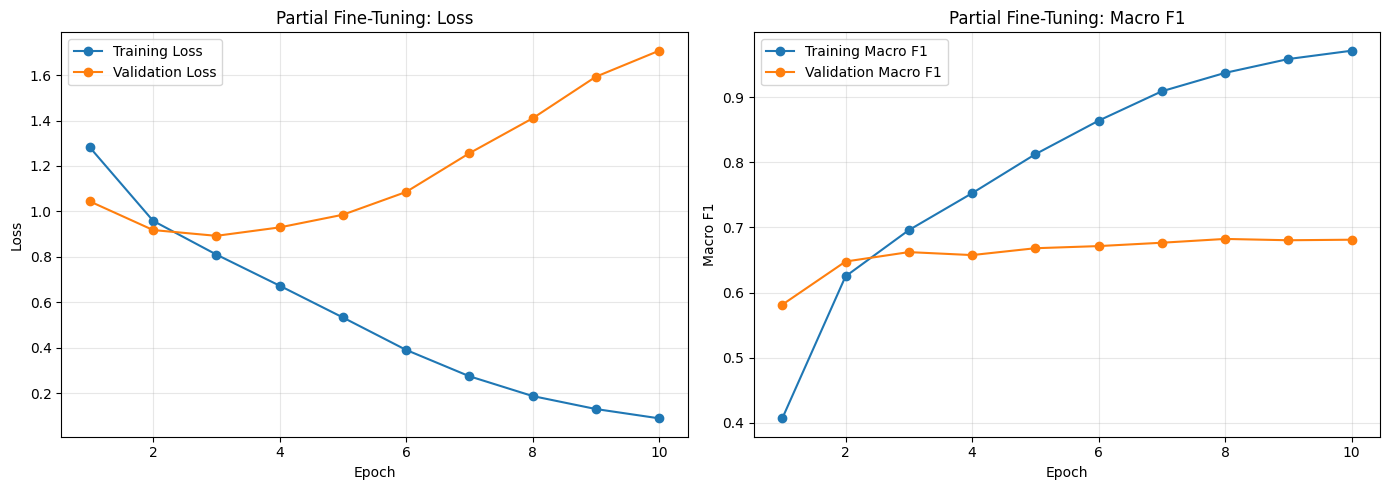

In [60]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    finetune_history_df["Epoch"],
    finetune_history_df["Training Loss"],
    marker="o",
    label="Training Loss"
)

axes[0].plot(
    finetune_history_df["Epoch"],
    finetune_history_df["Validation Loss"],
    marker="o",
    label="Validation Loss"
)

axes[0].set_title("Partial Fine-Tuning: Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    finetune_history_df["Epoch"],
    finetune_history_df["Training Macro F1"],
    marker="o",
    label="Training Macro F1"
)

axes[1].plot(
    finetune_history_df["Epoch"],
    finetune_history_df["Validation Macro F1"],
    marker="o",
    label="Validation Macro F1"
)

axes[1].set_title("Partial Fine-Tuning: Macro F1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Macro F1")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [62]:

# Load best checkpoint
finetuned_state = torch.load(
    "/content/best_finetuned_distilbert.pt",
    map_location=device,
    weights_only=True
)

finetuned_distil_model.load_state_dict(finetuned_state)
finetuned_distil_model.eval()

# Test evaluation
(
    ft_test_loss,
    ft_test_accuracy,
    ft_test_f1,
    ft_y_true,
    ft_y_pred
) = evaluate_model(
    finetuned_distil_model,
    distil_test_loader
)

ft_test_precision = precision_score(
    ft_y_true,
    ft_y_pred,
    average="macro",
    zero_division=0
)

ft_test_recall = recall_score(
    ft_y_true,
    ft_y_pred,
    average="macro",
    zero_division=0
)

print("PARTIALLY FINE-TUNED DISTILBERT")
print("--------------------------------")
print("Test Loss:", round(ft_test_loss, 4))
print("Accuracy:", round(ft_test_accuracy, 4))
print("Macro Precision:", round(ft_test_precision, 4))
print("Macro Recall:", round(ft_test_recall, 4))
print("Macro F1:", round(ft_test_f1, 4))

print("\nClassification Report:\n")

print(classification_report(
    ft_y_true,
    ft_y_pred,
    labels=np.arange(num_labels),
    target_names=label_encoder.classes_,
    zero_division=0
))


PARTIALLY FINE-TUNED DISTILBERT
--------------------------------
Test Loss: 1.501
Accuracy: 0.6806
Macro Precision: 0.6811
Macro Recall: 0.6776
Macro F1: 0.6782

Classification Report:

              precision    recall  f1-score   support

       anger       0.62      0.58      0.60       378
     disgust       0.44      0.34      0.38        85
        fear       0.68      0.69      0.68       426
         joy       0.76      0.74      0.75      1047
     neutral       0.69      0.76      0.72       146
     sadness       0.65      0.70      0.67       618
       shame       1.00      1.00      1.00        14
    surprise       0.61      0.61      0.61       401

    accuracy                           0.68      3115
   macro avg       0.68      0.68      0.68      3115
weighted avg       0.68      0.68      0.68      3115



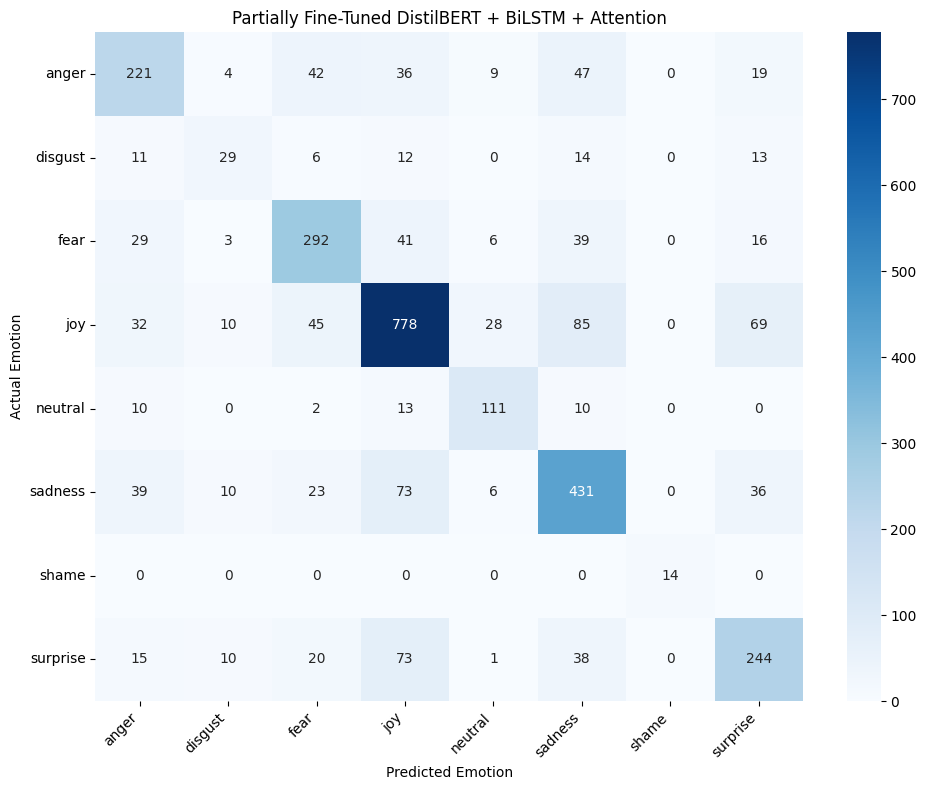

In [63]:

ft_cm = confusion_matrix(
    ft_y_true,
    ft_y_pred,
    labels=np.arange(num_labels)
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    ft_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title(
    "Partially Fine-Tuned DistilBERT + BiLSTM + Attention"
)

plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()


In [64]:

class FocalLoss(nn.Module):

    def __init__(self, gamma=1.5):
        super().__init__()
        self.gamma = gamma

    def forward(self, logits, targets):

        ce_loss = F.cross_entropy(
            logits,
            targets,
            reduction="none"
        )

        pt = torch.exp(-ce_loss)

        focal_loss = (
            (1 - pt) ** self.gamma
        ) * ce_loss

        return focal_loss.mean()


focal_criterion = FocalLoss(gamma=1.5).to(device)

print("Focal Loss initialized!")
print("Gamma:", 1.5)
print("Class weights: None")


Focal Loss initialized!
Gamma: 1.5
Class weights: None


In [65]:

focal_encoder = AutoModel.from_pretrained(
    "distilbert-base-uncased"
).to(device)

# Freeze all encoder parameters
for param in focal_encoder.parameters():
    param.requires_grad = False

# Unfreeze final two transformer layers
for layer in focal_encoder.transformer.layer[-2:]:
    for param in layer.parameters():
        param.requires_grad = True

focal_model = DistilBERT_BiLSTM_Attention_FT(
    bert_model=focal_encoder,
    hidden_size=256,
    num_classes=num_labels,
    dropout=0.3
).to(device)

focal_bert_params = [
    p for p in focal_model.bert.parameters()
    if p.requires_grad
]

focal_classifier_params = (
    list(focal_model.lstm.parameters()) +
    list(focal_model.attention.parameters()) +
    list(focal_model.classifier.parameters())
)

focal_optimizer = AdamW(
    [
        {"params": focal_bert_params, "lr": 2e-5},
        {"params": focal_classifier_params, "lr": 5e-4}
    ],
    weight_decay=0.01
)

print("Fresh Focal Loss model initialized!")


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Fresh Focal Loss model initialized!


In [66]:


def train_focal_epoch(
    model,
    loader,
    optimizer,
    scheduler,
    focal_criterion
):
    model.train()

    total_loss = 0
    all_preds = []
    all_labels = []

    for batch in loader:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        loss = focal_criterion(outputs, labels)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            filter(
                lambda p: p.requires_grad,
                model.parameters()
            ),
            max_norm=1.0
        )

        optimizer.step()
        scheduler.step()

        total_loss += loss.item()

        predictions = torch.argmax(outputs, dim=1)

        all_preds.extend(
            predictions.detach().cpu().numpy()
        )
        all_labels.extend(
            labels.detach().cpu().numpy()
        )

    avg_loss = total_loss / len(loader)

    macro_f1 = f1_score(
        all_labels,
        all_preds,
        average="macro",
        zero_division=0
    )

    return avg_loss, macro_f1


In [67]:

def evaluate_focal(
    model,
    loader,
    focal_criterion
):
    model.eval()

    total_loss = 0
    all_preds = []
    all_labels = []

    with torch.no_grad():

        for batch in loader:

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            loss = focal_criterion(outputs, labels)

            total_loss += loss.item()

            predictions = torch.argmax(outputs, dim=1)

            all_preds.extend(
                predictions.cpu().numpy()
            )
            all_labels.extend(
                labels.cpu().numpy()
            )

    avg_loss = total_loss / len(loader)

    accuracy = accuracy_score(
        all_labels,
        all_preds
    )

    macro_f1 = f1_score(
        all_labels,
        all_preds,
        average="macro",
        zero_division=0
    )

    return (
        avg_loss,
        accuracy,
        macro_f1,
        all_labels,
        all_preds
    )


In [68]:

EPOCHS = 10
PATIENCE = 3

total_steps = len(distil_train_loader) * EPOCHS

focal_scheduler = get_linear_schedule_with_warmup(
    focal_optimizer,
    num_warmup_steps=int(0.1 * total_steps),
    num_training_steps=total_steps
)

print("Focal Loss scheduler initialized!")
print("Training batches:", len(distil_train_loader))
print("Maximum epochs:", EPOCHS)
print("Early stopping patience:", PATIENCE)


Focal Loss scheduler initialized!
Training batches: 1558
Maximum epochs: 10
Early stopping patience: 3


In [73]:

import torch.nn.functional as F

print("PyTorch functional imported successfully!")


PyTorch functional imported successfully!


In [74]:

# Test the existing Focal Loss function

dummy_logits = torch.randn(4, num_labels).to(device)
dummy_labels = torch.tensor([0, 1, 2, 3]).to(device)

test_loss = focal_criterion(dummy_logits, dummy_labels)

print("Focal Loss test:", test_loss.item())
print("Focal Loss working correctly!")


Focal Loss test: 3.204606056213379
Focal Loss working correctly!


In [75]:

focal_history = []

best_focal_f1 = -1
best_focal_state = None
focal_patience_counter = 0

focal_start = time.time()

for epoch in range(EPOCHS):

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")

    # Training with Focal Loss
    train_loss, train_f1 = train_focal_epoch(
        focal_model,
        distil_train_loader,
        focal_optimizer,
        focal_scheduler,
        focal_criterion
    )

    # Validation
    (
        val_loss,
        val_accuracy,
        val_f1,
        _,
        _
    ) = evaluate_focal(
        focal_model,
        distil_val_loader,
        focal_criterion
    )

    focal_history.append({
        "Epoch": epoch + 1,
        "Training Loss": train_loss,
        "Training Macro F1": train_f1,
        "Validation Loss": val_loss,
        "Validation Accuracy": val_accuracy,
        "Validation Macro F1": val_f1
    })

    print(f"Training Loss: {train_loss:.4f}")
    print(f"Training Macro F1: {train_f1:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_accuracy:.4f}")
    print(f"Validation Macro F1: {val_f1:.4f}")

    # Save best checkpoint
    if val_f1 > best_focal_f1:

        best_focal_f1 = val_f1

        best_focal_state = copy.deepcopy(
            focal_model.state_dict()
        )

        focal_patience_counter = 0

        torch.save(
            best_focal_state,
            "/content/best_focal_distilbert.pt"
        )

        print("Best Focal Loss checkpoint saved!")

    else:
        focal_patience_counter += 1
        print("No validation improvement.")

    if focal_patience_counter >= PATIENCE:
        print("\nEarly stopping triggered.")
        break

focal_training_time = time.time() - focal_start

if best_focal_state is not None:
    focal_model.load_state_dict(best_focal_state)

focal_history_df = pd.DataFrame(focal_history)

print("\nFocal Loss training completed!")
print("Best Validation Macro F1:", round(best_focal_f1, 4))
print(
    "Training time:",
    round(focal_training_time / 60, 2),
    "minutes"
)

display(focal_history_df.round(4))



Epoch 1/10
Training Loss: 0.9064
Training Macro F1: 0.4248
Validation Loss: 0.7013
Validation Accuracy: 0.6247
Validation Macro F1: 0.6077
Best Focal Loss checkpoint saved!

Epoch 2/10
Training Loss: 0.6304
Training Macro F1: 0.6330
Validation Loss: 0.6119
Validation Accuracy: 0.6629
Validation Macro F1: 0.6444
Best Focal Loss checkpoint saved!

Epoch 3/10
Training Loss: 0.5163
Training Macro F1: 0.6882
Validation Loss: 0.5890
Validation Accuracy: 0.6809
Validation Macro F1: 0.6531
Best Focal Loss checkpoint saved!

Epoch 4/10
Training Loss: 0.4060
Training Macro F1: 0.7533
Validation Loss: 0.5983
Validation Accuracy: 0.6819
Validation Macro F1: 0.6682
Best Focal Loss checkpoint saved!

Epoch 5/10
Training Loss: 0.3022
Training Macro F1: 0.8089
Validation Loss: 0.6360
Validation Accuracy: 0.6889
Validation Macro F1: 0.6754
Best Focal Loss checkpoint saved!

Epoch 6/10
Training Loss: 0.2073
Training Macro F1: 0.8663
Validation Loss: 0.7200
Validation Accuracy: 0.6966
Validation Macro F

,Epoch,Training Loss,Training Macro F1,Validation Loss,Validation Accuracy,Validation Macro F1
0,1,0.9064,0.4248,0.7013,0.6247,0.6077
1,2,0.6304,0.6330,0.6119,0.6629,0.6444
2,3,0.5163,0.6882,0.5890,0.6809,0.6531
3,4,0.4060,0.7533,0.5983,0.6819,0.6682
4,5,0.3022,0.8089,0.6360,0.6889,0.6754
5,6,0.2073,0.8663,0.7200,0.6966,0.6896
6,7,0.1399,0.9080,0.8108,0.6799,0.6625
7,8,0.0893,0.9380,0.9157,0.6854,0.6653
8,9,0.0563,0.9589,1.0214,0.6867,0.6685


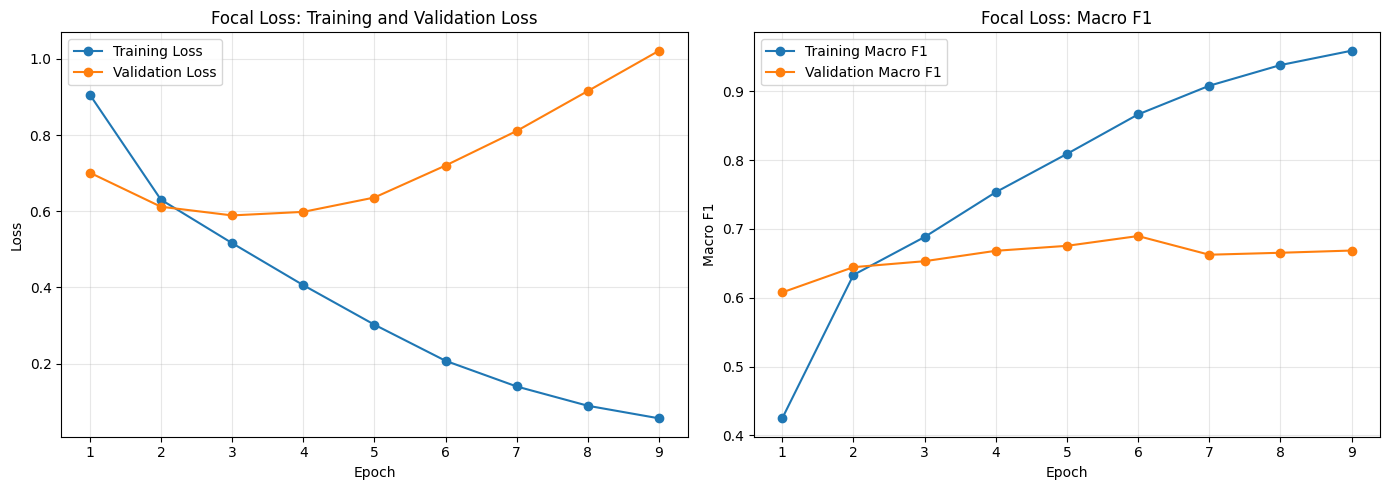

In [76]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    focal_history_df["Epoch"],
    focal_history_df["Training Loss"],
    marker="o",
    label="Training Loss"
)

axes[0].plot(
    focal_history_df["Epoch"],
    focal_history_df["Validation Loss"],
    marker="o",
    label="Validation Loss"
)

axes[0].set_title("Focal Loss: Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    focal_history_df["Epoch"],
    focal_history_df["Training Macro F1"],
    marker="o",
    label="Training Macro F1"
)

axes[1].plot(
    focal_history_df["Epoch"],
    focal_history_df["Validation Macro F1"],
    marker="o",
    label="Validation Macro F1"
)

axes[1].set_title("Focal Loss: Macro F1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Macro F1")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [78]:

# Load the best validation checkpoint
best_focal_state = torch.load(
    "/content/best_focal_distilbert.pt",
    map_location=device,
    weights_only=True
)

focal_model.load_state_dict(best_focal_state)
focal_model.eval()

# Evaluate on test set
(
    focal_test_loss,
    focal_test_accuracy,
    focal_test_f1,
    focal_y_true,
    focal_y_pred
) = evaluate_focal(
    focal_model,
    distil_test_loader,
    focal_criterion
)

focal_test_precision = precision_score(
    focal_y_true,
    focal_y_pred,
    average="macro",
    zero_division=0
)

focal_test_recall = recall_score(
    focal_y_true,
    focal_y_pred,
    average="macro",
    zero_division=0
)

print("DISTILBERT + BiLSTM + ATTENTION + FOCAL LOSS")
print("--------------------------------------------")
print("Test Loss:", round(focal_test_loss, 4))
print("Accuracy:", round(focal_test_accuracy, 4))
print("Macro Precision:", round(focal_test_precision, 4))
print("Macro Recall:", round(focal_test_recall, 4))
print("Macro F1:", round(focal_test_f1, 4))

print("\nClassification Report:\n")

print(classification_report(
    focal_y_true,
    focal_y_pred,
    labels=np.arange(num_labels),
    target_names=label_encoder.classes_,
    zero_division=0
))


DISTILBERT + BiLSTM + ATTENTION + FOCAL LOSS
--------------------------------------------
Test Loss: 0.7512
Accuracy: 0.6828
Macro Precision: 0.6921
Macro Recall: 0.6668
Macro F1: 0.6784

Classification Report:

              precision    recall  f1-score   support

       anger       0.61      0.61      0.61       378
     disgust       0.47      0.40      0.43        85
        fear       0.69      0.64      0.66       426
         joy       0.73      0.79      0.76      1047
     neutral       0.72      0.72      0.72       146
     sadness       0.65      0.68      0.67       618
       shame       1.00      0.93      0.96        14
    surprise       0.66      0.57      0.61       401

    accuracy                           0.68      3115
   macro avg       0.69      0.67      0.68      3115
weighted avg       0.68      0.68      0.68      3115



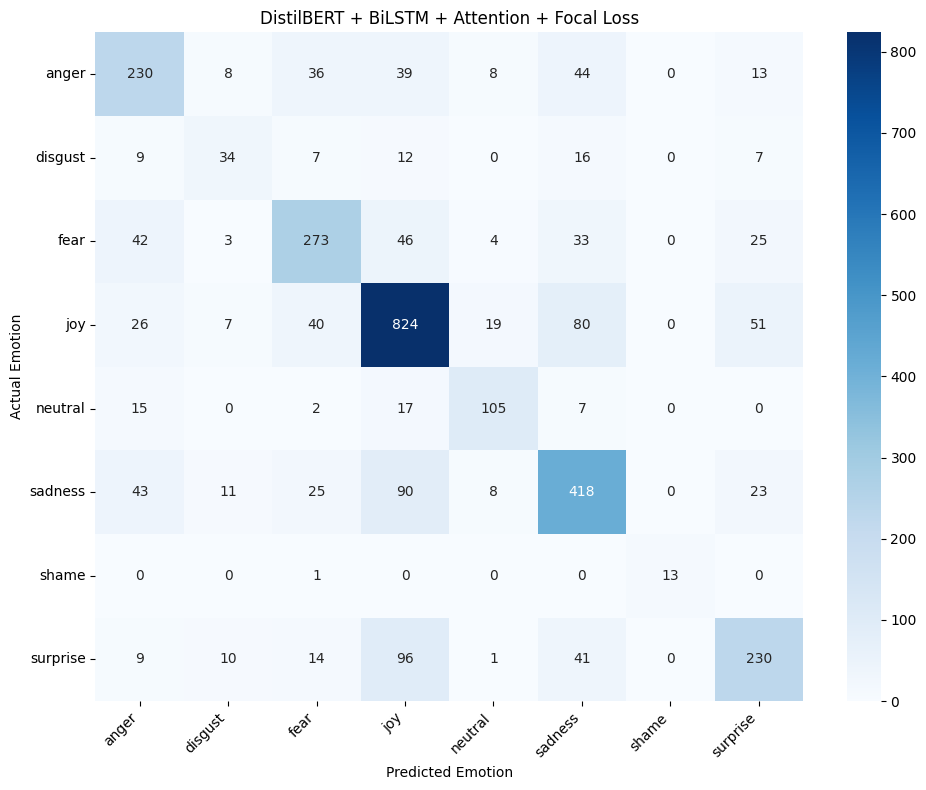

In [79]:

focal_cm = confusion_matrix(
    focal_y_true,
    focal_y_pred,
    labels=np.arange(num_labels)
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    focal_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("DistilBERT + BiLSTM + Attention + Focal Loss")
plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()


In [80]:


import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import copy
import time

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Fresh pretrained DistilBERT
gamma1_encoder = AutoModel.from_pretrained(
    "distilbert-base-uncased"
).to(device)

# Freeze all transformer layers
for param in gamma1_encoder.parameters():
    param.requires_grad = False

# Unfreeze final two transformer layers
for layer in gamma1_encoder.transformer.layer[-2:]:
    for param in layer.parameters():
        param.requires_grad = True

# Create fresh hybrid model
gamma1_model = DistilBERT_BiLSTM_Attention_FT(
    bert_model=gamma1_encoder,
    hidden_size=256,
    num_classes=num_labels,
    dropout=0.3
).to(device)

# Focal Loss gamma = 1.0
gamma1_criterion = FocalLoss(gamma=1.0).to(device)

# Separate learning rates
gamma1_bert_params = [
    p for p in gamma1_model.bert.parameters()
    if p.requires_grad
]

gamma1_classifier_params = (
    list(gamma1_model.lstm.parameters()) +
    list(gamma1_model.attention.parameters()) +
    list(gamma1_model.classifier.parameters())
)

gamma1_optimizer = AdamW(
    [
        {"params": gamma1_bert_params, "lr": 2e-5},
        {"params": gamma1_classifier_params, "lr": 5e-4}
    ],
    weight_decay=0.01
)

EPOCHS = 10
PATIENCE = 3

total_steps = len(distil_train_loader) * EPOCHS

gamma1_scheduler = get_linear_schedule_with_warmup(
    gamma1_optimizer,
    num_warmup_steps=int(0.1 * total_steps),
    num_training_steps=total_steps
)

print("Experiment A initialized!")
print("Architecture: DistilBERT + BiLSTM + Attention")
print("Focal Loss gamma: 1.0")
print("Transformer learning rate: 2e-5")
print("Classifier learning rate: 5e-4")
print("Dropout: 0.3")
print("Weight decay: 0.01")


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Experiment A initialized!
Architecture: DistilBERT + BiLSTM + Attention
Focal Loss gamma: 1.0
Transformer learning rate: 2e-5
Classifier learning rate: 5e-4
Dropout: 0.3
Weight decay: 0.01


In [7]:
import torch

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU unavailable. Currently using CPU.")

Device: cpu
GPU unavailable. Currently using CPU.


In [10]:

gamma1_history = []

best_gamma1_f1 = -1
best_gamma1_state = None
gamma1_patience = 0

gamma1_start = time.time()

for epoch in range(EPOCHS):

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")

    train_loss, train_f1 = train_focal_epoch(
        gamma1_model,
        distil_train_loader,
        gamma1_optimizer,
        gamma1_scheduler,
        gamma1_criterion
    )

    (
        val_loss,
        val_accuracy,
        val_f1,
        _,
        _
    ) = evaluate_focal(
        gamma1_model,
        distil_val_loader,
        gamma1_criterion
    )

    gamma1_history.append({
        "Epoch": epoch + 1,
        "Training Loss": train_loss,
        "Training Macro F1": train_f1,
        "Validation Loss": val_loss,
        "Validation Accuracy": val_accuracy,
        "Validation Macro F1": val_f1
    })

    print(f"Training Loss: {train_loss:.4f}")
    print(f"Training Macro F1: {train_f1:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_accuracy:.4f}")
    print(f"Validation Macro F1: {val_f1:.4f}")

    if val_f1 > best_gamma1_f1:

        best_gamma1_f1 = val_f1

        best_gamma1_state = copy.deepcopy(
            gamma1_model.state_dict()
        )

        gamma1_patience = 0

        torch.save(
            best_gamma1_state,
            "/content/best_gamma1_distilbert.pt"
        )

        print("Best gamma 1.0 checkpoint saved!")

    else:
        gamma1_patience += 1
        print("No validation improvement.")

    if gamma1_patience >= PATIENCE:
        print("\nEarly stopping triggered.")
        break

gamma1_training_time = time.time() - gamma1_start

gamma1_model.load_state_dict(best_gamma1_state)

gamma1_history_df = pd.DataFrame(gamma1_history)

print("\nGamma 1.0 training completed!")
print("Best validation Macro F1:", round(best_gamma1_f1, 4))
print(
    "Training time:",
    round(gamma1_training_time / 60, 2),
    "minutes"
)

display(gamma1_history_df.round(4))


NameError: name 'EPOCHS' is not defined

In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    gamma1_history_df["Epoch"],
    gamma1_history_df["Training Loss"],
    marker="o",
    label="Training Loss"
)

axes[0].plot(
    gamma1_history_df["Epoch"],
    gamma1_history_df["Validation Loss"],
    marker="o",
    label="Validation Loss"
)

axes[0].set_title("Focal Loss Gamma 1.0: Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    gamma1_history_df["Epoch"],
    gamma1_history_df["Training Macro F1"],
    marker="o",
    label="Training Macro F1"
)

axes[1].plot(
    gamma1_history_df["Epoch"],
    gamma1_history_df["Validation Macro F1"],
    marker="o",
    label="Validation Macro F1"
)

axes[1].set_title("Focal Loss Gamma 1.0: Macro F1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Macro F1")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()
